<a href="https://colab.research.google.com/github/Jiayi-Eva-Wang/econ3916-midterm-project/blob/main/midterm_starter_(5).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 Midterm Project — Econometric Foundation

**ECON 3916 · Applied Data Analytics** · Topics 1-14 · 100 points · your role: Independent analyst

This is the **starter**: the structure of the project in rubric order. Fill the empty cells and keep every heading so the grader finds each section. The brief on Canvas has the full text of every section and the rubric. The grader reruns this notebook from the top, so every number, table and figure in your report must come from a cell here.

**🛑 This project is entirely NO AI.** Not phases one to three — all of it. No AI for the code, the analysis, the writing, or the editing. This is the one assessment in the course that establishes you can do the work unaided, and it is the one you will draw on when an interviewer asks what you built. Everything you have practised with a co-pilot, you do here alone.

## Start here

Work top to bottom. What each part of this notebook is for:

1. **Data provenance**: where the file came from. It feeds Section 1 and your README.
2. **Section 1**: load the data into a DataFrame called `df`, then run the *Section 1 self-check* cell and answer the questions under it. Do this before the **Mon 2 Nov** checkpoint.
3. **Section 2**: figures, each with a caption that states a finding.
4. **Section 3**: the OLS model, with a draft committed by **Fri 6 Nov**.
5. **Section 4**: diagnostics, only after Topic 14.
6. **Section 5**: words only.
7. **Numbers my report quotes**: last. Every number in the report must be printed there.

The brief's *Six checks before you post* list the problems that came up most often in Checkpoint 1. Read them before you settle on your controls.

## Setup

Imports only. Add any others you need here, at the top.

In [119]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [120]:
# Read the original CSV files from the public GitHub repository
DATA_URL = "https://raw.githubusercontent.com/Jiayi-Eva-Wang/econ3916-midterm-project/main/"

# earnings
earnings_2022 = pd.read_csv("earnings_states_2022_B20004 (1).csv",dtype=str)
earnings_2023 = pd.read_csv("earnings_states_2023_B20004 (1).csv",dtype=str)
earnings_2024 = pd.read_csv("earnings_states_2024_B20004 (1).csv",dtype=str)

#age
age_2022 = pd.read_csv("age_2022_B01002 (3).csv",dtype=str)
age_2023 = pd.read_csv("age_2023_B01002 (3).csv",dtype=str)
age_2024 = pd.read_csv("age_2024_B01002 (3).csv",dtype=str)

# education
education_2022 = pd.read_csv("education_2022_B15003 (3).csv",dtype=str)
education_2023 = pd.read_csv("education_2023_B15003 (3).csv",dtype=str)
education_2024 = pd.read_csv("education_2024_B15003 (3).csv",dtype=str)

# poopulation
population_2022 = pd.read_csv("population_states_2022_B01003.csv",dtype=str)
population_2023 = pd.read_csv("population_states_2023_B01003.csv",dtype=str)
population_2024 = pd.read_csv("population_states_2024_B01003.csv",dtype=str)

print("All 12 CSV files loaded from GitHub.")

All 12 CSV files loaded from GitHub.


## Data provenance

Fill these in when you download the data. They feed Section 1 and your README.

In [121]:
SOURCE_URL = "https://data.census.gov/"
DOWNLOAD_DATE = ["2026-11-05", "2026-11-08", "2026-11-09"]
FILE_NAME = ["education_2022_B15003.csv", "education_2023_B15003.csv", "education_2024_B15003.csv",
             "age_2022_B01002.csv", "age_2023_B01002.csv", "age_2024_B01002.csv",
             "earnings_states_2022_B20004.csv", "earnings_states_2023_B20004.csv", "earnings_states_2024_B20004.csv",
             "population_states_2022_B01003.csv", "population_states_2023_B01003.csv", "population_states_2024_B01003.csv"]


**Who collected it, for what purpose, what is missing and why?**

The U.S. Census Bureau collected these data through the American Community Survey to produce demographic, social, economic, and housing estimates. This study uses the 2022-2024 ACS 1-Year Estimates Detailed Tables: B15003 (educational attainment), B20004 (median annual earnings among adults aged 25+ with earnings), B01003 (total population), and B01002 (median age).

The final dataset includes 150 state-year observations for the 50 states, excluding DC and Puerto Rico. No model variables are missing after the data are merged. However, complete published estimates do not mean there was no survey nonresponse or measurement error. These aggregate tables alone cannot establish the missingness mechanism.

## Section 1: The Question and the Data (20 pts)

State the question in one sentence, and say why it matters and to whom. Describe the data as a product of measurement decisions, name the missingness mechanism (MCAR, MAR or MNAR) and defend the label. Build a summary-statistics table a reader can read without asking you a question.

In [122]:
# Store the three original population tables
population_tables = {2022: population_2022, 2023: population_2023, 2024: population_2024}
population_results = []

# Clean each year using the same steps
for year, table in population_tables.items():
    clean = table.iloc[0, 1:].reset_index()
    clean.columns = ["state", "population"]
    clean = clean[clean["state"].str.endswith("!!Estimate")].copy()
    clean["state"] = clean["state"].str.replace("!!Estimate", "", regex=False).str.strip()
    clean["population"] = pd.to_numeric(clean["population"].str.replace(",", "", regex=False), errors="raise")
    clean = clean[~clean["state"].isin(["United States", "District of Columbia", "Puerto Rico"])].copy()
    clean["year"] = year
    assert len(clean) == 50, f"Expected 50 states in {year}"
    assert clean["state"].is_unique, f"Duplicate states in {year}"
    assert clean["population"].gt(0).all(), f"Invalid population in {year}"
    population_results.append(clean)

# Stack the three years
population_clean = pd.concat(population_results, ignore_index=True)
print("Total rows:", len(population_clean))
print(population_clean.groupby("year").size())
display(population_clean.head())

Total rows: 150
year
2022    50
2023    50
2024    50
dtype: int64


,state,population,year
0,Alabama,5074296,2022
1,Alaska,733583,2022
2,Arizona,7359197,2022
3,Arkansas,3045637,2022
4,California,39029342,2022


In [123]:
# Store the three original earnings tables
earnings_tables = {2022: earnings_2022, 2023: earnings_2023, 2024: earnings_2024}
earnings_results = []

# Select overall median earnings and clean each year
for year, table in earnings_tables.items():
    clean = table.iloc[0, 1:].reset_index()
    clean.columns = ["state", "earnings"]
    clean = clean[clean["state"].str.endswith("!!Estimate")].copy()
    clean["state"] = clean["state"].str.replace("!!Estimate", "", regex=False).str.strip()
    clean["earnings"] = pd.to_numeric(clean["earnings"].str.replace(",", "", regex=False), errors="raise")
    clean = clean[~clean["state"].isin(["United States", "District of Columbia", "Puerto Rico"])].copy()
    clean["year"] = year
    assert len(clean) == 50, f"Expected 50 states in {year}"
    assert clean["state"].is_unique, f"Duplicate states in {year}"
    assert clean["earnings"].gt(0).all(), f"Invalid earnings in {year}"
    earnings_results.append(clean)

# Stack the three years; earnings are still in each year's dollars
earnings_clean = pd.concat(earnings_results, ignore_index=True)
print("Total rows:", len(earnings_clean))
print(earnings_clean.groupby("year").size())
display(earnings_clean.head())

Total rows: 150
year
2022    50
2023    50
2024    50
dtype: int64


,state,earnings,year
0,Alabama,42463,2022
1,Alaska,53582,2022
2,Arizona,48738,2022
3,Arkansas,41385,2022
4,California,52520,2022


In [124]:
# Store the three original age tables
age_tables = {2022: age_2022, 2023: age_2023, 2024: age_2024}
age_results = []

# Find the Total row and clean each year
for year, table in age_tables.items():
    total_row = table[table.iloc[:, 0].str.strip().eq("Total:")]
    assert len(total_row) == 1, f"Expected one Total row in {year}"
    clean = total_row.iloc[0, 1:].reset_index()
    clean.columns = ["state", "median_age"]
    clean = clean[clean["state"].str.endswith("!!Estimate")].copy()
    clean["state"] = clean["state"].str.replace("!!Estimate", "", regex=False).str.strip()
    clean["median_age"] = pd.to_numeric(clean["median_age"].str.replace(",", "", regex=False), errors="raise")
    clean = clean[~clean["state"].isin(["United States", "District of Columbia", "Puerto Rico"])].copy()
    clean["year"] = year
    assert len(clean) == 50, f"Expected 50 states in {year}"
    assert clean["state"].is_unique, f"Duplicate states in {year}"
    assert clean["median_age"].between(0, 100).all(), f"Invalid median age in {year}"
    age_results.append(clean)

# Stack the three years
age_clean = pd.concat(age_results, ignore_index=True)
print("Total rows:", len(age_clean))
print(age_clean.groupby("year").size())
display(age_clean.head())

Total rows: 150
year
2022    50
2023    50
2024    50
dtype: int64


,state,median_age,year
0,Alabama,39.6,2022
1,Alaska,35.9,2022
2,Arizona,38.8,2022
3,Arkansas,38.9,2022
4,California,37.9,2022


In [125]:
# Display all educational attainment categories
print(education_2024.iloc[:, 0].to_string())

0                                           Total:
1                           No schooling completed
2                                   Nursery school
3                                     Kindergarten
4                                        1st grade
5                                        2nd grade
6                                        3rd grade
7                                        4th grade
8                                        5th grade
9                                        6th grade
10                                       7th grade
11                                       8th grade
12                                       9th grade
13                                      10th grade
14                                      11th grade
15                          12th grade, no diploma
16                     Regular high school diploma
17                   GED or alternative credential
18                  Some college, less than 1 year
19        Some college, 1 or mo

In [126]:
# Use the same approximate schooling-year assignments for all years
schooling_years = [0, 0, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 12, 12, 12.5, 13.5, 14, 16, 18, 19, 21]
education_tables = {2022: education_2022, 2023: education_2023, 2024: education_2024}
education_results = []

# Calculate average schooling for each year
for year, table in education_tables.items():
    counts = table.loc[:, table.columns.str.endswith("!!Estimate")].copy()
    counts = counts.replace(",", "", regex=True).apply(pd.to_numeric, errors="raise")
    assert len(counts) == 25, f"Expected a total and 24 attainment categories in {year}"
    assert counts.notna().all().all(), f"Missing education counts in {year}"
    assert counts.iloc[1:25].sum().eq(counts.iloc[0]).all(), f"Category totals do not match in {year}"
    assert counts.iloc[0].gt(0).all(), f"Invalid population totals in {year}"
    weighted_years = counts.iloc[1:25].mul(schooling_years, axis=0).sum()
    average_schooling = weighted_years / counts.iloc[0]
    clean = average_schooling.rename_axis("state").reset_index(name="schooling_years")
    clean["state"] = clean["state"].str.replace("!!Estimate", "", regex=False).str.strip()
    clean = clean[~clean["state"].isin(["United States", "District of Columbia", "Puerto Rico"])].copy()
    clean["year"] = year
    assert len(clean) == 50, f"Expected 50 states in {year}"
    assert clean["state"].is_unique, f"Duplicate states in {year}"
    assert clean["schooling_years"].between(0, 21).all(), f"Invalid schooling values in {year}"
    education_results.append(clean)

# Stack the three years
education_clean = pd.concat(education_results, ignore_index=True)
print("Total rows:", len(education_clean))
print(education_clean.groupby("year").size())
display(education_clean.head())

Total rows: 150
year
2022    50
2023    50
2024    50
dtype: int64


,state,schooling_years,year
0,Alabama,13.470410,2022
1,Alaska,13.749985,2022
2,Arizona,13.618420,2022
3,Arkansas,13.255237,2022
4,California,13.382819,2022


In [127]:
# merge the four datasets by state and year
df = pd.merge(population_clean, earnings_clean, on=["state", "year"], how="outer", validate="one_to_one")
df = pd.merge(df, age_clean, on=["state", "year"], how="outer", validate="one_to_one")
df = pd.merge(df, education_clean, on=["state", "year"], how="outer", validate="one_to_one")

# Check sample size, unique state-year pairs, and missing values
assert len(df) == 150, "Expected 150 rows"
assert not df.duplicated(["state", "year"]).any(), "Duplicate state-year observations"
assert df.groupby("year").size().eq(50).all(), "Expected 50 states per year"
assert df.notna().all().all(), "Missing values found after merging"

# Check variable ranges
assert df["population"].gt(0).all(), "Invalid population"
assert df["earnings"].gt(0).all(), "Invalid earnings"
assert df["median_age"].between(0, 100).all(), "Invalid median age"
assert df["schooling_years"].between(0, 21).all(), "Invalid schooling years"

# Calculate log population and sort the data
df["log_population"] = np.log(df["population"])
df = df.sort_values(["year", "state"]).reset_index(drop=True)

print("Total observations:", len(df))
print(df.groupby("year").size())
display(df.head())

Total observations: 150
year
2022    50
2023    50
2024    50
dtype: int64


,state,population,year,earnings,median_age,schooling_years,log_population
0,Alabama,5074296,2022,42463,39.6,13.470410,15.439698
1,Alaska,733583,2022,53582,35.9,13.749985,13.505696
2,Arizona,7359197,2022,48738,38.8,13.618420,15.811461
3,Arkansas,3045637,2022,41385,38.9,13.255237,14.929221
4,California,39029342,2022,52520,37.9,13.382819,17.479824


In [128]:
# Section 1 self-check: run once your data is loaded into a DataFrame called df.
# It prints what Section 1 has to report. It doesn't judge your choices: answer the questions below.
UNIT = "state-year"        # one row is one what? e.g. "county" or "country-year"
OUTCOME = "earnings"     # your dependent variable's column name
MAIN_X = "schooling_years"      # your main explanatory variable's column name
CONTROLS = ["log_population", "median_age"]    # every other column in your model

if "df" in globals():
    print(f"Rows: {len(df):,}   Columns: {df.shape[1]}   One row is: {UNIT or '(fill in UNIT)'}")
    cols = [c for c in [OUTCOME, MAIN_X, *CONTROLS] if c]
    absent = [c for c in cols if c not in df.columns]
    if absent:
        print("Not in df:", absent)
    present = [c for c in cols if c in df.columns]
    if present:
        print("\nMissing values per column:")
        print(df[present].isna().sum().to_string())
    if OUTCOME in df.columns and pd.api.types.is_numeric_dtype(df[OUTCOME]):
        print(f"\nSkew of {OUTCOME}: {df[OUTCOME].skew():.2f} (above about 1, consider a log)")
else:
    print("Load your data into a DataFrame called df first, then run this cell.")

Rows: 150   Columns: 7   One row is: state-year

Missing values per column:
earnings           0
schooling_years    0
log_population     0
median_age         0

Skew of earnings: 0.58 (above about 1, consider a log)


In [129]:
# Reshape the variables into a long table
summary_long_table = df.melt(id_vars="year", value_vars=["earnings", "schooling_years", "population", "median_age", "log_population"], var_name="Variable", value_name="Value")

# Calculate summary statistics by year and variable
summary_table = summary_long_table.groupby(["year", "Variable"])["Value"].agg(["mean", "median", "std", "min", "max", "count"])
summary_table.columns = ["Mean", "Median", "SD", "Min", "Max", "N"]
summary_table.index.names = ["Year", "Variable"]

# Display rounded statistics
display(summary_table.round(2))

Mean      Median          SD        Min  \
Year Variable                                                         
2022 earnings           49119.24    48499.50     5534.19   40342.00   
     log_population        15.23       15.33        1.02      13.27   
     median_age            39.33       39.15        2.15      32.10   
     population       6652315.18  4551275.50  7451008.03  581381.00   
     schooling_years       13.77       13.78        0.31      13.21   
2023 earnings           50883.44    50132.50     5548.30   41175.00   
     log_population        15.23       15.33        1.02      13.28   
     median_age            39.54       39.35        2.13      32.30   
     population       6684718.48  4549951.50  7488403.38  584057.00   
     schooling_years       13.79       13.80        0.31      13.19   
2024 earnings           53173.48    51441.00     5429.95   44889.00   
     log_population        15.24       15.34        1.02      13.28   
     median_age            39.62       39.40        2.12      32.50   
     population       6788174.80  4593056.00  7630882.69  587618.00   
     schooling_years       13.83       13.85        0.30      13.24   

                              Max   N  
Year Variable                          
2022 earnings            62009.00  50  
     log_population         17.48  50  
     median_age             45.10  50  
     population       39029342.00  50  
     schooling_years        14.46  50  
2023 earnings            65055.00  50  
     log_population         17.48  50  
     median_age             44.90  50  
     population       38965193.00  50  
     schooling_years        14.41  50  
2024 earnings            66968.00  50  
     log_population         17.49  50  
     median_age             44.90  50  
     population       39431263.00  50  
     schooling_years        14.44  50

**Table 1. Summary statistics for the 50 U.S. states, 2022-2024.**

Each state receives equal weight in the statistics. Earnings are measured in current-year dollars; schooling and median age in years; population in persons; and log population as the natural logarithm of population. Source: U.S. Census Bureau, ACS 1-Year Estimates, Tables B15003, B20004, B01003 and B01002.

**Answer before you go on.**

1. For each control: does your main explanatory variable change it? If yes, it is on the path from X to Y. Drop it, or run with and without and say what each version measures.
2. Are all your variables in the same units and for the same years?
3. If your question is about a policy, where is the period before it?

Answers:
1. Median age controls for state age structure, which may be related to both schooling and earnings, while log population accounts for state size. Because the data do not establish whether these controls are causes or consequences of schooling, I will compare models with and without them. The results therefore describe overall and conditional associations, respectively, rather than causal effects.

2. Yes, all variables are matched by state and year for 2022-2024.
Earnings are in current-year dollars for adults aged 25+ with earnings. Estimated schooling is measured in years for all adults aged 25+. Median age is in years, and population in persons, both cover the entire state population. Statewide median age serves as a broad control for age structure.

3. This is not a policy question.

This study examines the relationship between estimated average schooling and median annual earnings across U.S. states, controlling for population size and median age. It uses 2022-2024 ACS 1-Year Estimates, covering 150 state-year observations with no missing values for the model variables. Years of schooling are estimated from attainment categories, and summary statistics give each state equal weight.

Schooling measurement: The estimated average schooling is calculated by assigning years to each educational attainment category and weighting them by the number of adults in that category. No schooling, nursery school, and kindergarten are coded as 0; grades 1-11 use their grade number; grade 12 without a diploma, a high school diploma, and a GED are coded as 12. Some college under one year is coded as 12.5; some college of one or more years without a degree is coded as 13.5; an associate's degree is coded as 14; a bachelor's degree as 16; a master's degree as 18; a professional degree as 19; and a doctorate as 21. These are approximations rather than the exact number of years attended.

## Section 2: Descriptive Evidence (20 pts)

Show the reader the data before any model. At least two figures, each with a caption that states its finding, not its variables. Chapter 3's standards for axes. If the outcome is skewed, show it and say what you will do about it.

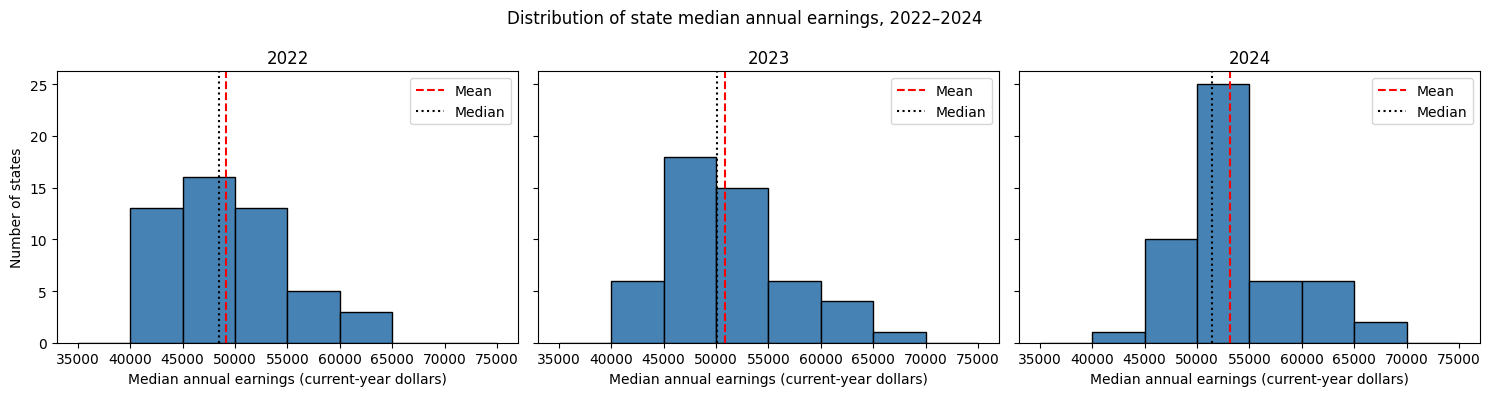

In [130]:
# Plot earnings distributions separately for each year
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)

for ax, year in zip(axes, [2022, 2023, 2024]):
    values = df.loc[df["year"] == year, "earnings"]
    ax.hist(values, bins=np.arange(35000, 75001, 5000), color="steelblue", edgecolor="black")
    ax.axvline(values.mean(), color="red", linestyle="--", label="Mean")
    ax.axvline(values.median(), color="black", linestyle=":", label="Median")
    ax.set_title(str(year))
    ax.set_xlabel("Median annual earnings (current-year dollars)")
    ax.legend()

axes[0].set_ylabel("Number of states")
fig.suptitle("Distribution of state median annual earnings, 2022–2024")
plt.tight_layout()
plt.show()

**Figure 1. State median earnings are right-skewed each year, with means above medians.**

Each panel includes 50 states. Red dashed lines indicate means, and black dotted lines indicate medians. Earnings are measured in current-year dollars, so year-to-year changes do not by themselves reflect changes in purchasing power. Source: U.S. Census Bureau, ACS 1-Year Estimates, Table B20004, 2022-2024.

Earnings are retained at the dollar level for interpretation. OLS does not require a normally distributed outcome; residual behavior is examined in Section 4.

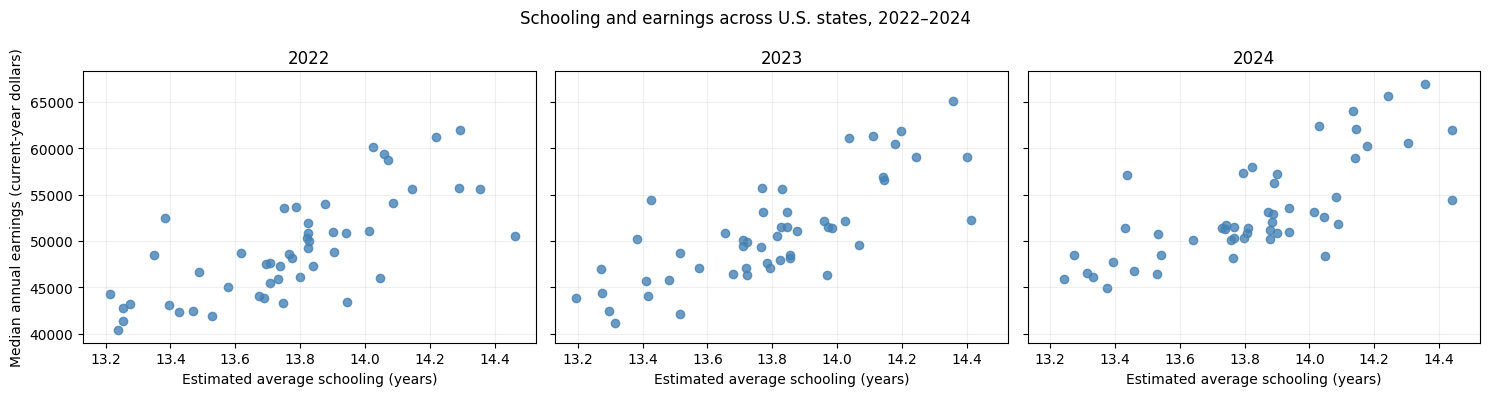

In [131]:
# Plot schooling and earnings separately by year
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)

for ax, year in zip(axes, [2022, 2023, 2024]):
    sample = df[df["year"] == year]
    ax.scatter(sample["schooling_years"], sample["earnings"], color="steelblue", alpha=0.8)
    ax.set_title(str(year))
    ax.set_xlabel("Estimated average schooling (years)")
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Median annual earnings (current-year dollars)")
fig.suptitle("Schooling and earnings across U.S. states, 2022–2024")
plt.tight_layout()
plt.show()

**Figure 2. Higher estimated average schooling is associated with higher median annual earnings in all three years.**

Each point represents one state. These plots show unadjusted associations and do not account for population size or median age and do not establish causality. Source: U.S. Census Bureau, ACS 1-Year Estimates, Tables B15003 and B20004, 2022-2024.

## Section 3: The Model (25 pts)

Fit a multivariate OLS model and report it in a formatted regression table (coefficients, standard errors, N, R-squared), not a `summary()` dump. Interpret at least two coefficients in full: magnitude, units, direction, precision. For every control, say whether it blocks a confounding path or adds precision, and what would make it a bad control (Chapter 10). OLS only: no difference-in-differences estimate.

In [132]:
# Estimate annual models with and without controls
models_uncontrolled = {}
models_controlled = {}

for year in [2022, 2023, 2024]:
    sample = df[df["year"] == year]
    models_uncontrolled[year] = smf.ols(
        "earnings ~ schooling_years", data=sample).fit(cov_type="HC3")
    models_controlled[year] = smf.ols(
        "earnings ~ schooling_years + log_population + median_age", data=sample).fit(cov_type="HC3")
#Display schooling coefficients and confidence intervals
for year in [2022, 2023, 2024]:
    for label, model in [("Uncontrolled", models_uncontrolled[year]), ("Controlled", models_controlled[year])]:
        interval = model.conf_int().loc["schooling_years"]

        print(f"{year} {label}: schooling coefficient = {model.params['schooling_years']:.2f}, 95% CI [{interval.iloc[0]:.2f}, {
            interval.iloc[1]:.2f}], N = {int(model.nobs)}, R-squared = {model.rsquared:.3f}")

2022 Uncontrolled: schooling coefficient = 13309.38, 95% CI [9044.67, 17574.10], N = 50, R-squared = 0.541
2022 Controlled: schooling coefficient = 14814.51, 95% CI [11077.59, 18551.43], N = 50, R-squared = 0.633
2023 Uncontrolled: schooling coefficient = 13902.47, 95% CI [9903.00, 17901.94], N = 50, R-squared = 0.589
2023 Controlled: schooling coefficient = 14999.86, 95% CI [11494.71, 18505.02], N = 50, R-squared = 0.681
2024 Uncontrolled: schooling coefficient = 13309.49, 95% CI [9300.65, 17318.33], N = 50, R-squared = 0.555
2024 Controlled: schooling coefficient = 14663.56, 95% CI [11144.82, 18182.30], N = 50, R-squared = 0.660


In [133]:
# A formatted regression table for all six models (Table A1)
regression_table = {}

for year in [2022, 2023, 2024]:
    for label, model in [("Uncontrolled", models_uncontrolled[year]), ("Controlled", models_controlled[year])]:
        column = {}
        for variable in ["schooling_years", "log_population", "median_age", "Intercept"]:
            column[variable] = f"{model.params[variable]:,.2f}" if variable in model.params else ""
            column[variable + " (SE)"] = f"({model.bse[variable]:,.2f})" if variable in model.params else ""
        column["N"] = int(model.nobs)
        column["R-squared"] = f"{model.rsquared:.3f}"
        regression_table[f"{year} {label}"] = column

regression_table = pd.DataFrame(regression_table)
display(regression_table)

,2022 Uncontrolled,2022 Controlled,2023 Uncontrolled,2023 Controlled,2024 Uncontrolled,2024 Controlled
schooling_years,"13,309.38","14,814.51","13,902.47","14,999.86","13,309.49","14,663.56"
schooling_years (SE),"(2,175.91)","(1,906.63)","(2,040.58)","(1,788.38)","(2,045.36)","(1,795.31)"
log_population,,"1,428.54",,"1,592.56",,"1,568.84"
log_population (SE),,(598.35),,(576.37),,(601.04)
median_age,,-368.18,,-174.85,,-275.49
median_age (SE),,(324.70),,(284.89),,(304.58)
Intercept,"-134,187.39","-162,184.78","-140,870.03","-173,347.23","-130,884.09","-162,608.01"
Intercept (SE),"(29,774.35)","(28,123.99)","(28,001.53)","(27,351.46)","(28,082.39)","(27,315.78)"
N,50,50,50,50,50,50
R-squared,0.541,0.633,0.589,0.681,0.555,0.660


**Table A1. Annual OLS regressions of state median earnings on estimated average schooling and controls.**

Earnings are measured in current-year dollars, with HC3 robust standard errors in parentheses. Each model covers all 50 states. Uncontrolled models include only schooling, while controlled models also include log population and median age.

In [134]:
# Display all coefficients and confidence intervals for the 2024 controlled model
model = models_controlled[2024]
coefficient_details = pd.DataFrame({"Coefficient": model.params, "HC3 SE": model.bse, "95% CI lower": model.conf_int()[0], "95% CI upper": model.conf_int()[1]})
display(coefficient_details.round(2))

,Coefficient,HC3 SE,95% CI lower,95% CI upper
Intercept,-162608.01,27315.78,-216145.95,-109070.08
schooling_years,14663.56,1795.31,11144.82,18182.30
log_population,1568.84,601.04,390.82,2746.86
median_age,-275.49,304.58,-872.46,321.48


In [135]:
# Calculate interpretable changes for the 2024 controlled model
model = models_controlled[2024]
schooling_change = model.params["schooling_years"] * 0.1
schooling_interval = model.conf_int().loc["schooling_years"] * 0.1
population_change = model.params["log_population"] * np.log(1.10)
population_interval = model.conf_int().loc["log_population"] * np.log(1.10)
print(f"0.1-year higher schooling: ${schooling_change:.2f}, 95% CI [${
    schooling_interval.iloc[0]:.2f}, ${schooling_interval.iloc[1]:.2f}]")
print(f"10% larger population: ${population_change:.2f}, 95% CI [${
    population_interval.iloc[0]:.2f}, ${population_interval.iloc[1]:.2f}]")

0.1-year higher schooling: $1466.36, 95% CI [$1114.48, $1818.23]
10% larger population: $149.53, 95% CI [$37.25, $261.80]


**Schooling:** In 2024, a 0.1-year increase in estimated average schooling level is associated with approximately $1,466 higher median annual earnings, holding log population and median age constant (95% CI: $1,114-$1,818). This is a conditional state-level association, not an individual-level causal return to schooling.

**Population:** With schooling and median age constant, a 10% increase in state population is associated with an approximately $150 increase in median annual earnings (95% CI: $37-$262). This estimate is calculated by multiplying the log-population coefficient by ln(1.10).

**Median age:** Holding the other variables constant, each one-year increase in a state’s median age is associated with approximately $275 lower median annual earnings. The 95% confidence interval ranges from $872 lower to $321 higher, meaning the estimate is consistent with both negative and positive associations.

**Model comparison:** The schooling coefficient is positive in all three years,
with or without controls. Adding controls increases the schooling coefficient slightly. The controlled models have R-squared values of 0.633-0.681. These patterns do not establish causality, and coefficients are expressed in each year’s dollars.

## Section 4: Diagnostics (20 pts)

Residuals against fitted values and against your main predictor; a constant-variance check, with robust standard errors if it fails; variance inflation factors, interpreted; at least one influential-observation check.

**Start only after Topic 14.** Write Sections 1 to 3 first; they do not depend on it.

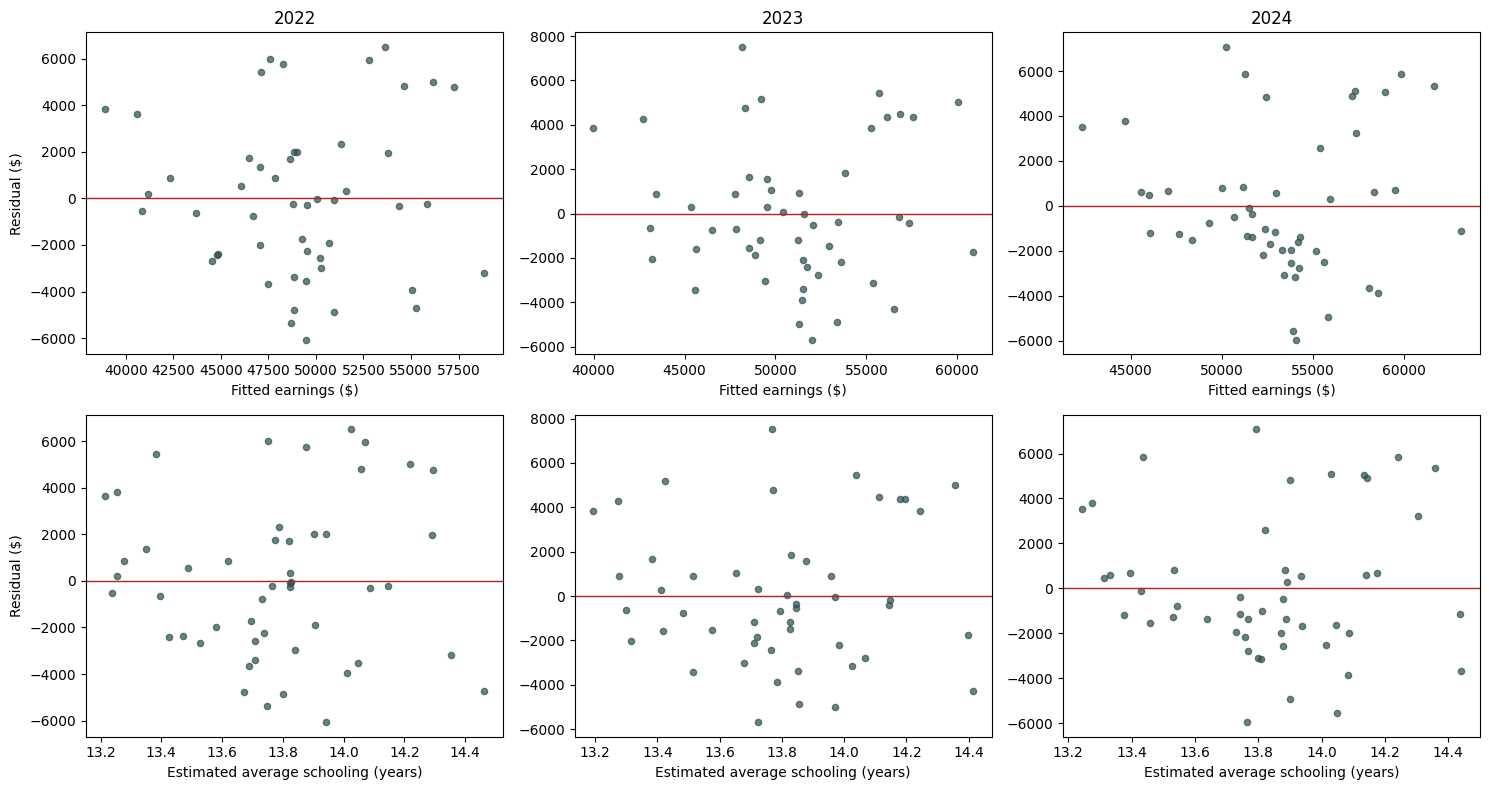

In [136]:
# Fit annual OLS models for diagnostics
diagnostic_models = {}
features = ["schooling_years", "log_population", "median_age"]

for year in [2022, 2023, 2024]:
    sample = df[df["year"] == year].copy()
    diagnostic_models[year] = sm.OLS(sample["earnings"], sm.add_constant(sample[features])).fit()

# Plot residuals against fitted values and schooling
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for column, year in enumerate([2022, 2023, 2024]):
    sample = df[df["year"] == year]
    res = diagnostic_models[year]
    axes[0, column].scatter(res.fittedvalues, res.resid, s=20, alpha=0.7, color="darkslategray")
    axes[0, column].axhline(0, color="firebrick", lw=1)
    axes[0, column].set_title(str(year))
    axes[0, column].set_xlabel("Fitted earnings ($)")
    axes[1, column].scatter(sample["schooling_years"], res.resid, s=20, alpha=0.7, color="darkslategray")
    axes[1, column].axhline(0, color="firebrick", lw=1)
    axes[1, column].set_xlabel("Estimated average schooling (years)")

axes[0, 0].set_ylabel("Residual ($)")
axes[1, 0].set_ylabel("Residual ($)")
plt.tight_layout()
plt.show()

Residual plots show several large deviations, with some clustering below zero in the middle ranges. No consistent funnel pattern appears across the three years. These plots do not confirm constant variance or a correct functional form; formal tests and influence checks follow.

In [137]:
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import jarque_bera

# Test heteroskedasticity and residual normality for each year
for year, res in diagnostic_models.items():
    bp = het_breuschpagan(res.resid, res.model.exog)
    jb = jarque_bera(res.resid)
    print(f"{year}: Breusch-Pagan p={bp[1]:.4f}, Jarque-Bera p={jb[1]:.4f}")

2022: Breusch-Pagan p=0.2192, Jarque-Bera p=0.3783
2023: Breusch-Pagan p=0.2961, Jarque-Bera p=0.3441
2024: Breusch-Pagan p=0.2082, Jarque-Bera p=0.2900


Breusch-Pagan p-values range from 0.2082 to 0.2961, providing no strong evidence against constant error variance. Jarque-Bera p-values range from 0.2900 to 0.3783, providing no strong evidence against residual normality. These tests do not prove that the assumptions hold, so HC3 robust standard errors are retained across all models.

In [138]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Calculate VIFs for each annual model
for year, res in diagnostic_models.items():
    X = res.model.exog
    print(f"\n{year} VIF:")
    for i, name in enumerate(res.model.exog_names):
        if name != "const":
          print(f"{name}: {variance_inflation_factor(X, i):.2f}")


2022 VIF:
schooling_years: 1.09
log_population: 1.04
median_age: 1.07

2023 VIF:
schooling_years: 1.07
log_population: 1.04
median_age: 1.06

2024 VIF:
schooling_years: 1.07
log_population: 1.06
median_age: 1.07


Across the annual models, VIFs range from 1.04 to 1.09. These values are close to one, indicating little variance inflation due to linear relationships among the predictors.

In [139]:
# Identify the five most influential states in each year
influence_results = {}

for year, res in diagnostic_models.items():
    sample = df[df["year"] == year].copy()
    infl = res.get_influence()
    lev = infl.hat_matrix_diag
    std_resid = infl.resid_studentized_internal
    cooks = infl.cooks_distance[0]
    order = np.argsort(cooks)[::-1][:5]
    top5 = sample.iloc[order][["state", "year"]].copy()
    top5["leverage"] = lev[order]
    top5["standardized_residual"] = std_resid[order]
    top5["cooks_distance"] = cooks[order]
    influence_results[year] = top5
    print(f"\n{year}: Five largest Cook's distances")
    display(top5.round(4))


2022: Five largest Cook's distances


,state,year,leverage,standardized_residual,cooks_distance
43,Utah,2022,0.3092,-1.3730,0.2109
1,Alaska,2022,0.1456,1.8735,0.1495
44,Vermont,2022,0.1929,-1.5180,0.1377
4,California,2022,0.1362,1.6881,0.1124
8,Florida,2022,0.1451,-1.4958,0.0949



2023: Five largest Cook's distances


,state,year,leverage,standardized_residual,cooks_distance
93,Utah,2023,0.3076,-1.1719,0.1525
58,Florida,2023,0.1439,-1.9000,0.1517
94,Vermont,2023,0.1905,-1.4751,0.1281
54,California,2023,0.1346,1.7222,0.1153
97,West Virginia,2023,0.1968,1.3261,0.1077



2024: Five largest Cook's distances


,state,year,leverage,standardized_residual,cooks_distance
143,Utah,2024,0.3058,-1.4232,0.2231
108,Florida,2024,0.1447,-1.9719,0.1644
104,California,2024,0.1349,1.9267,0.1448
101,Alaska,2024,0.1537,1.6116,0.1179
144,Vermont,2024,0.1894,-1.2449,0.0905


In [140]:
# Refit each annual model without its most influential state
models_without_top = {}
sensitivity_results = []

for year, res in diagnostic_models.items():
    sample = df[df["year"] == year].copy()
    cooks = res.get_influence().cooks_distance[0]
    top = np.argsort(cooks)[::-1][0]
    top_state = sample.iloc[top]["state"]
    trimmed = sample.drop(sample.index[top])
    refit = sm.OLS(trimmed["earnings"], sm.add_constant(trimmed[features])).fit(cov_type="HC3")
    models_without_top[year] = refit
    original = models_controlled[year].params["schooling_years"]
    revised = refit.params["schooling_years"]
    interval = refit.conf_int().loc["schooling_years"]
    sensitivity_results.append([year, top_state, original, revised, 100 * (revised - original) / original, interval.iloc[0], interval.iloc[1], int(refit.nobs)])

# Compare schooling estimates before and after exclusion
sensitivity_table = pd.DataFrame(sensitivity_results, columns=["Year", "Excluded state", "Original coefficient", "Revised coefficient", "Change (%)", "95% CI lower", "95% CI upper", "N"])
display(sensitivity_table.round(2))

,Year,Excluded state,Original coefficient,Revised coefficient,Change (%),95% CI lower,95% CI upper,N
0,2022,Utah,14814.51,15440.49,4.23,11309.09,19571.89,49
1,2023,Utah,14999.86,15449.76,3.00,11636.93,19262.59,49
2,2024,Utah,14663.56,15221.02,3.80,11434.12,19007.92,49


**Table A2. The positive schooling association persists after excluding Utah, the most influential state in each year.**

Schooling coefficients increase by 3.00%-4.23%, and all 95% confidence intervals remain above zero. HC3 robust confidence intervals are reported. Each reduced sample contains 49 states.

However, Utah is retained in the main models because influence alone is not a reason to remove a valid observation. Its exclusion is a sensitivity check, not a change to the main sample.

## Section 5: Threats and Conclusion (10 pts)

First the threats: what would have to be true for your main coefficient to be causal, is it, and if not, what your estimate is instead. Then the conclusion: what you found, how confident a reader should be, and what you would do with another month. Half a page. No new results, so there is no code cell here.

After accounting for population and median age, the model would need to have no omitted factors that affect both schooling and earnings, no reverse causality, and an adequate specification. The constructed schooling measure would also need to accurately represent educational attainment.

These conditions are not established, as states differ in industry composition, living costs, and other characteristics that the model does not control for. Higher earnings opportunities may also attract educated workers. Years of schooling are approximated from qualifications, while schooling and earnings data cover different population groups. Passing diagnostic tests does not establish causal identification.

Instead, it is a state-level conditional association: the difference in median earnings associated with higher estimated average schooling, holding population size and median age constant. It is not the income gain an individual would receive from another year of education.

To conclude, the schooling association is positive in all three years. In 2024, 0.1 additional years of state average schooling corresponds to approximately $1,466 higher median annual earnings (95% CI: $1,114-$1,818). Excluding Utah changes the annual schooling coefficients by 3.00%-4.23%, but does not change their direction. These results support a consistent positive association but do not establish causality because omitted variables and reverse causality remain possible. Because the same states appear each year, the three estimates are not independent replications.

With another month, I would test different values for the years of schooling assigned to each education category, add theoretically justified measures of industry composition, and adjust earnings for regional price differences.

## Appendix

The regression table, the diagnostics output and any extra figures. The appendix does not count toward the 6–8 page limit of the report.

Table A1 is displayed in Section 3. Diagnostic plots, test results, influence checks, and Table A2 are displayed in Section 4. These materials will appear in the appendix of the written report. Table 1 and Figures 1-2 will remain in the report's main text.

## Numbers my report quotes

Every number in your report, each with a name that says where it comes from. A number in the report that this cell does not print is unsupported, and is graded as if it were missing. Keep it the last code cell.

In [141]:
# Sample sizes and annual model results
REPORT_NUMBERS = {"Final sample size": len(df), "Number of states": df["state"].nunique()}

for year in [2022, 2023, 2024]:
    sample = df[df["year"] == year]
    model = models_controlled[year]
    interval = model.conf_int().loc["schooling_years"]
    REPORT_NUMBERS[f"{year}: sample size"] = len(sample)
    REPORT_NUMBERS[f"{year}: mean earnings"] = sample["earnings"].mean()
    REPORT_NUMBERS[f"{year}: median earnings"] = sample["earnings"].median()
    REPORT_NUMBERS[f"{year}: controlled schooling coefficient"] = model.params["schooling_years"]
    REPORT_NUMBERS[f"{year}: schooling CI lower"] = interval.iloc[0]
    REPORT_NUMBERS[f"{year}: schooling CI upper"] = interval.iloc[1]
    REPORT_NUMBERS[f"{year}: controlled R-squared"] = model.rsquared
    REPORT_NUMBERS[f"{year}: uncontrolled schooling coefficient"] = models_uncontrolled[year].params["schooling_years"]
    REPORT_NUMBERS[f"{year}: Breusch-Pagan p-value"] = het_breuschpagan(diagnostic_models[year].resid, diagnostic_models[year].model.exog)[1]
    REPORT_NUMBERS[f"{year}: Jarque-Bera p-value"] = jarque_bera(diagnostic_models[year].resid)[1]

# Interpretable changes for the 2024 model
model = models_controlled[2024]
REPORT_NUMBERS["2024: earnings difference for 0.1-year higher schooling"] = model.params["schooling_years"] * 0.1
REPORT_NUMBERS["2024: 0.1-year schooling CI lower"] = model.conf_int().loc["schooling_years"].iloc[0] * 0.1
REPORT_NUMBERS["2024: 0.1-year schooling CI upper"] = model.conf_int().loc["schooling_years"].iloc[1] * 0.1
REPORT_NUMBERS["2024: earnings difference for 10% larger population"] = model.params["log_population"] * np.log(1.10)
REPORT_NUMBERS["2024: population difference CI lower"] = model.conf_int().loc["log_population"].iloc[0] * np.log(1.10)
REPORT_NUMBERS["2024: population difference CI upper"] = model.conf_int().loc["log_population"].iloc[1] * np.log(1.10)

# Influence sensitivity results
for _, row in sensitivity_table.iterrows():
    year = int(row["Year"])
    REPORT_NUMBERS[f"{year}: excluded state"] = row["Excluded state"]
    REPORT_NUMBERS[f"{year}: schooling coefficient change (%)"] = row["Change (%)"]

# All summary statistics
for (year, variable), row in summary_table.iterrows():
    for statistic, value in row.items():
        REPORT_NUMBERS[f"{year}: {variable} {statistic}"] = value

# All regression coefficients, standard errors, and confidence intervals
for year in [2022, 2023, 2024]:
    for label, result in [("Uncontrolled", models_uncontrolled[year]),
     ("Controlled", models_controlled[year])]:
        for term in result.params.index:
            REPORT_NUMBERS[f"{year}: {label} {term} coefficient"] = result.params[term]
            REPORT_NUMBERS[f"{year}: {label} {term} HC3 SE"] = result.bse[term]
            REPORT_NUMBERS[f"{year}: {label} {term} CI lower"] = result.conf_int().loc[term].iloc[0]
            REPORT_NUMBERS[f"{year}: {label} {term} CI upper"] = result.conf_int().loc[term].iloc[1]
        REPORT_NUMBERS[f"{year}: {label} R-squared"] = result.rsquared

# VIFs and influence diagnostics
for year, result in diagnostic_models.items():
    for i, term in enumerate(result.model.exog_names):
        if term != "const":
            REPORT_NUMBERS[f"{year}: {term} VIF"] = variance_inflation_factor(result.model.exog, i)
    for _, row in influence_results[year].iterrows():
        for term in ["leverage", "standardized_residual", "cooks_distance"]:
            REPORT_NUMBERS[f"{year}: {row['state']} {term}"] = row[term]

# Sensitivity-check estimates and confidence intervals
for _, row in sensitivity_table.iterrows():
    for term in ["Revised coefficient", "95% CI lower", "95% CI upper", "N"]:
        REPORT_NUMBERS[f"{int(row['Year'])}: without Utah {term}"] = row[term]

# print collected results
for name, value in REPORT_NUMBERS.items():
    print(f"{name}: {value}")

Final sample size: 150
Number of states: 50
2022: sample size: 50
2022: mean earnings: 49119.24
2022: median earnings: 48499.5
2022: controlled schooling coefficient: 14814.508097663687
2022: schooling CI lower: 11077.585096611614
2022: schooling CI upper: 18551.431098715762
2022: controlled R-squared: 0.6330675463888391
2022: uncontrolled schooling coefficient: 13309.384699645374
2022: Breusch-Pagan p-value: 0.21915991185444353
2022: Jarque-Bera p-value: 0.3783025529245857
2023: sample size: 50
2023: mean earnings: 50883.44
2023: median earnings: 50132.5
2023: controlled schooling coefficient: 14999.863586054387
2023: schooling CI lower: 11494.711491824697
2023: schooling CI upper: 18505.01568028408
2023: controlled R-squared: 0.6813372510440985
2023: uncontrolled schooling coefficient: 13902.470067111051
2023: Breusch-Pagan p-value: 0.29612930979845253
2023: Jarque-Bera p-value: 0.3440523988948922
2024: sample size: 50
2024: mean earnings: 53173.48
2024: median earnings: 51441.0
2024

## Checkpoints

In Colab, *File › Save a copy in GitHub* makes a commit each time you use it. Save at each checkpoint so the commit history shows it.

- [ ] **Mon 26 Oct:** your question and data source, posted in the Midterm checkpoint 1 discussion.
- [ ] **Mon 2 Nov:** your data loaded and your summary table, committed to your repository.
- [ ] **Fri 6 Nov:** a draft of your model, committed.
- [ ] **Mon 9 Nov, 11:59pm:** the project is due.

## Before you submit

- [ ] A Colab notebook with all your analysis, cleanly organised.
- [ ] A written report, 6 to 8 pages of text, uploaded as a PDF.
- [ ] A GitHub repository containing both, with a `README.md` you wrote yourself.
- [ ] **Question and data provenance (20):** A defensible measurable question; data described as a measurement product; missingness mechanism identified and defended; interpretable summary table
- [ ] **Descriptive evidence (20):** Two or more figures each making a stated point; captions state findings not variables; Chapter 3 standards met
- [ ] **Model and interpretation (25):** Properly formatted regression table; two coefficients interpreted in full including units and magnitude; every control justified by role
- [ ] **Diagnostics (20):** Residuals, heteroskedasticity, VIF and influence all run and interpreted; robust errors used where warranted
- [ ] **Threats and conclusion (10):** The causal claim assessed in plain terms; the estimand correctly labelled if not causal; conclusion adds no new results
- [ ] **Repository, checkpoints and reproducibility (5):** Public GitHub repo containing the notebook and the report; the two committed checkpoints visible in the commit history; data included or its download documented; a self-written README giving the question, the source, how to run it and the headline finding
- [ ] The Colab notebook is shared with *Anyone with the link*, and the link is in the Canvas submission box.
- [ ] Every number in the report is printed by the *Numbers my report quotes* cell.
- [ ] No AI anywhere: code, analysis, writing, editing, README.
- [ ] *File › Save a copy in GitHub*, path `Midterm Project/Econ_3916_Midterm.ipynb`.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.